# 02 - Data Exploration and Quality Control


This notebook performs initial quality control and exploratory
analysis of the merged gene expression count matrix and sample metadata.

In [34]:
import sys
sys.path.append("..")  # go up to the repo root

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pydeseq2.dds import DeseqDataSet
from src.data_validation import (
    validate_sample_alignment,
    validate_count_matrix,
    validate_metadata
)

from src.utils.visualization import save_figure


ModuleNotFoundError: No module named 'src.utils'

## 1. Data Loading and Validation

In [7]:
# Load processed datasets
counts_df = pd.read_csv(
    "../data/processed/raw_merged.csv",
    index_col=0
)

metadata = pd.read_csv(
    "../data/processed/metadata_merged.csv",
    index_col=0
)

In [20]:
# Validate sample alignment
metadata = validate_sample_alignment(counts_df, metadata)

# Validate count matrix
validate_count_matrix(counts_df)

# Validate metadata structure
validate_metadata(
    metadata,
    required_columns=["Condition"]
)

print(f"Count matrix shape: {counts_df.shape}")
print(f"Metadata shape: {metadata.shape}")

print("\nSamples per condition:")
print(metadata["Condition"].value_counts())

# Check missing metadata values
print("Missing values per column:")
display(metadata.isna().sum())

# Check condition distribution
print("\nCondition distribution:")
display(metadata["Condition"].value_counts())

Count matrix shape: (232, 59427)
Metadata shape: (232, 1)

Samples per condition:
Condition
Cancer     119
Healthy    113
Name: count, dtype: int64
Missing values per column:


Condition    0
dtype: int64


Condition distribution:


Condition
Cancer     119
Healthy    113
Name: count, dtype: int64

## 2. Raw Count Matrix Quality Control

This section evaluates the characteristics of the raw gene expression
count matrix, focusing on sequencing depth and data sparsity.

Library size

To detect differencies in sequencing depth between samples, we can calculate the library size for each sample by summing the counts across all genes. This will give us an idea of the total number of reads for each patient.


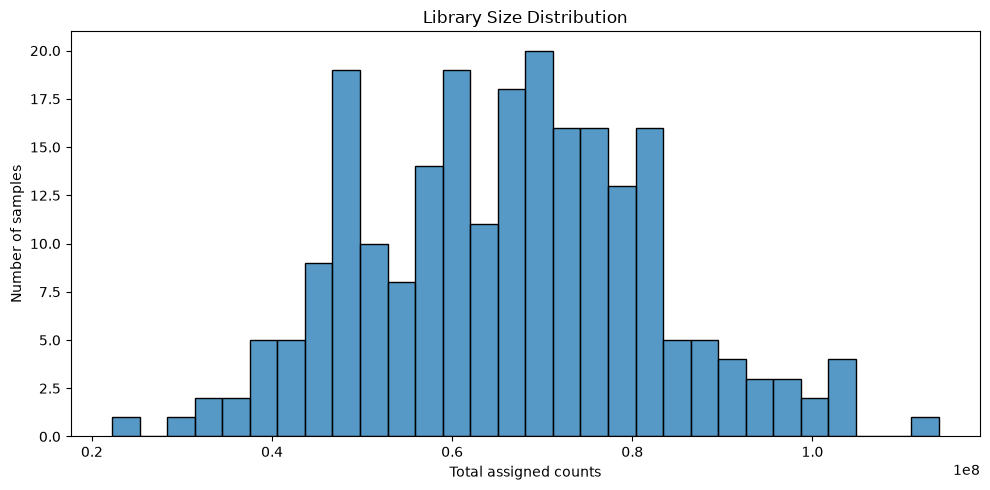

In [9]:
# Calculate library sizes (total assigned counts per sample)
library_sizes = counts_df.sum(axis=1)

# Visualize library size distribution
plt.figure(figsize=(10, 5))

sns.histplot(library_sizes, bins=30)

plt.xlabel("Total assigned counts")
plt.ylabel("Number of samples")
plt.title("Library Size Distribution")

plt.tight_layout()
plt.show()

In [10]:
# Calculate the percentage of zero counts
zero_percentage = (counts_df == 0).to_numpy().mean() * 100

# Count genes with no expression across all samples
zero_genes = (counts_df.sum(axis=0) == 0).sum()

print(f"Zero counts: {zero_percentage:.2f}%")
print(f"Genes with zero counts across all samples: {zero_genes}")

Zero counts: 42.16%
Genes with zero counts across all samples: 2868


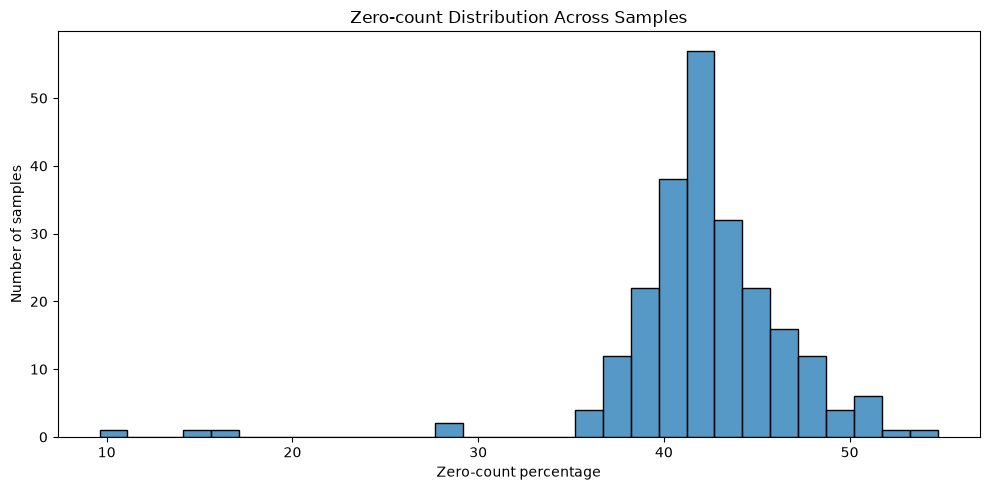

In [21]:
# Calculate zero-count percentage per sample
sample_zero_percentage = (counts_df == 0).mean(axis=1) * 100

plt.figure(figsize=(10, 5))

sns.histplot(sample_zero_percentage, bins=30)

plt.xlabel("Zero-count percentage")
plt.ylabel("Number of samples")
plt.title("Zero-count Distribution Across Samples")

plt.tight_layout()
plt.show()

## 3. Gene Filtering
Removal of Unexpressed Genes

Genes with zero counts across all samples provide no information
for downstream differential expression analysis.

These genes are removed to reduce the dimensionality of the
count matrix.

In [11]:
# Remove genes with zero counts across all samples
counts_filtered = counts_df.loc[:, counts_df.sum(axis=0) > 0].copy()

# Report filtering results
n_genes_removed = counts_df.shape[1] - counts_filtered.shape[1]

print(f"Original genes: {counts_df.shape[1]:,}")
print(f"Removed genes: {n_genes_removed:,}")
print(f"Remaining genes: {counts_filtered.shape[1]:,}")

print(f"Filtered matrix shape: {counts_filtered.shape}")

Original genes: 59,427
Removed genes: 2,868
Remaining genes: 56,559
Filtered matrix shape: (232, 56559)


## 4. Low-Expression Gene Filtering

Genes with consistently low expression across samples are removed
to reduce noise and improve downstream analysis.

A gene is retained if it has at least 10 counts in at least 10%
of the samples.

In [12]:
# Define filtering thresholds
min_counts = 10
min_sample_fraction = 0.10
min_samples = int(min_sample_fraction * counts_filtered.shape[0])

# Identify genes meeting the expression threshold
genes_to_keep = (
    (counts_filtered >= min_counts).sum(axis=0) >= min_samples
)

# Apply filtering
counts_filtered = counts_filtered.loc[:, genes_to_keep].copy()

# Report filtering results
n_genes_removed = (~genes_to_keep).sum()

print(f"Minimum counts: {min_counts}")
print(f"Minimum samples: {min_samples} ({min_sample_fraction:.0%})")

print(f"\nGenes before filtering: {genes_to_keep.size:,}")
print(f"Genes removed: {n_genes_removed:,}")
print(f"Genes retained: {counts_filtered.shape[1]:,}")

print(f"\nFiltered matrix shape: {counts_filtered.shape}")


Minimum counts: 10
Minimum samples: 23 (10%)

Genes before filtering: 56,559
Genes removed: 29,310
Genes retained: 27,249

Filtered matrix shape: (232, 27249)


In [13]:

# Number of samples meeting the expression threshold per retained gene
expressed_samples = (counts_filtered >= min_counts).sum(axis=0)

print("Distribution of expressed samples per retained gene:")
display(expressed_samples.describe())


Distribution of expressed samples per retained gene:


count    27249.000000
mean       184.600939
std         70.524435
min         23.000000
25%        143.000000
50%        231.000000
75%        232.000000
max        232.000000
dtype: float64

## 5. Variance Stabilizing Transformation (VST)

Raw RNA-seq counts exhibit a mean-variance dependency, where
the variance generally increases with the mean expression level.


The transformed expression matrix will be used for downstream
exploratory analyses, including PCA, clustering and visualization.

In [14]:
# Create metadata for exploratory analysis
metadata_eda = pd.DataFrame(index=counts_filtered.index)

# Initialize PyDESeq2 dataset
dds_eda = DeseqDataSet(
    counts=counts_filtered.astype(int),
    metadata=metadata_eda,
    design="~1",
    n_cpus=4
)

# Apply variance stabilizing transformation
dds_eda.vst(use_design=False)

# Extract transformed counts
vst_df = pd.DataFrame(
    dds_eda.layers["vst_counts"],
    index=counts_filtered.index,
    columns=counts_filtered.columns
)


Fit type used for VST : parametric
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.41 seconds.

Fitting dispersions...
... done in 15.64 seconds.



In [15]:
# Validate transformed matrix
assert vst_df.shape == counts_filtered.shape
assert vst_df.index.equals(counts_filtered.index)
assert vst_df.columns.equals(counts_filtered.columns)
assert np.isfinite(vst_df.to_numpy()).all()

print(f"VST matrix shape: {vst_df.shape}")
print("All values are finite.")


VST matrix shape: (232, 27249)
All values are finite.


In [16]:
display(vst_df.describe().loc[["min", "mean", "50%", "max"]])

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2MP1,A4GALT,A4GNT,AAAS,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
min,2.055360,3.391531,2.055360,13.639755,4.869984,3.267435,2.721840,7.481340,2.055360,9.565324,...,7.974546,6.781743,6.988211,9.334342,10.230052,3.102851,10.431792,10.005941,11.082262,10.647167
mean,4.420924,6.547140,3.265299,15.956185,7.098974,6.166651,5.010236,10.038193,3.531204,11.205919,...,9.684593,9.918675,8.772684,10.526088,11.193365,7.544077,11.857075,13.359035,12.353496,11.973590
50%,4.468220,6.671294,3.198230,16.091532,7.048893,5.717989,5.008165,10.042545,3.589973,11.213379,...,9.527560,9.900070,8.840774,10.491857,11.187614,7.555912,11.865989,13.425393,12.438210,12.004234
max,6.324594,8.222186,9.649705,18.416402,9.165118,13.533641,7.825215,12.582383,6.768519,12.188212,...,11.933708,14.482731,10.402469,12.595629,12.523690,11.521976,15.840306,15.083687,13.545359,13.232434


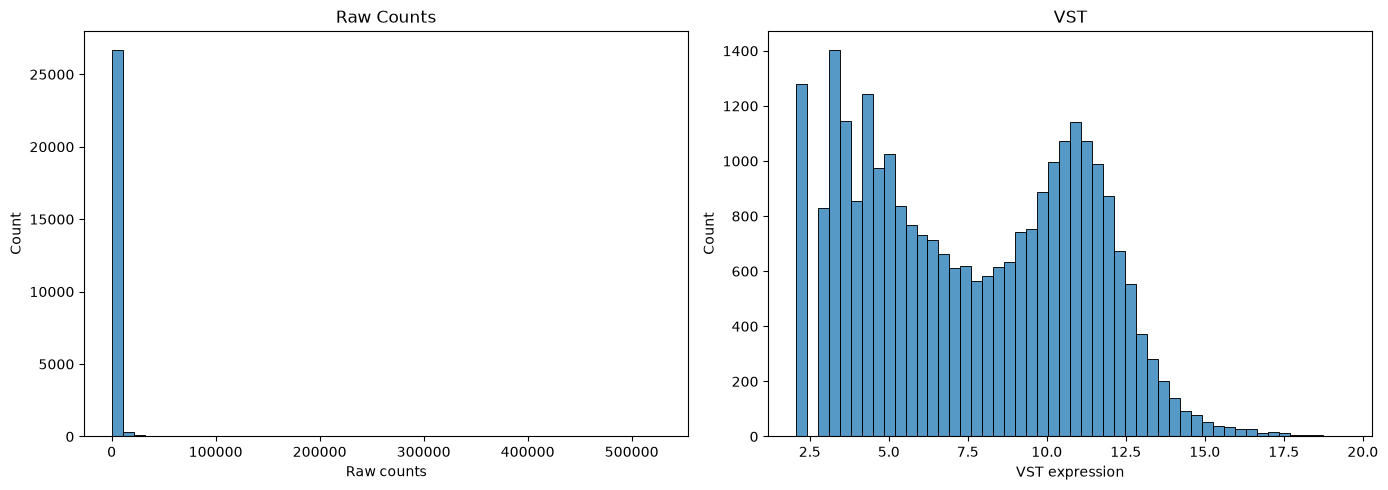

In [17]:
# Compare raw counts and VST for one sample
sample_id = counts_filtered.index[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    counts_filtered.loc[sample_id],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Raw Counts")
axes[0].set_xlabel("Raw counts")

sns.histplot(
    vst_df.loc[sample_id],
    bins=50,
    ax=axes[1]
)
axes[1].set_title("VST")
axes[1].set_xlabel("VST expression")

plt.tight_layout()
plt.show()


## 6. VST Quality Assessment

To assess the effectiveness of the variance stabilizing transformation,
we examine the relationship between mean expression and variance
across genes.

A successful transformation should reduce the dependency between
these two quantities.

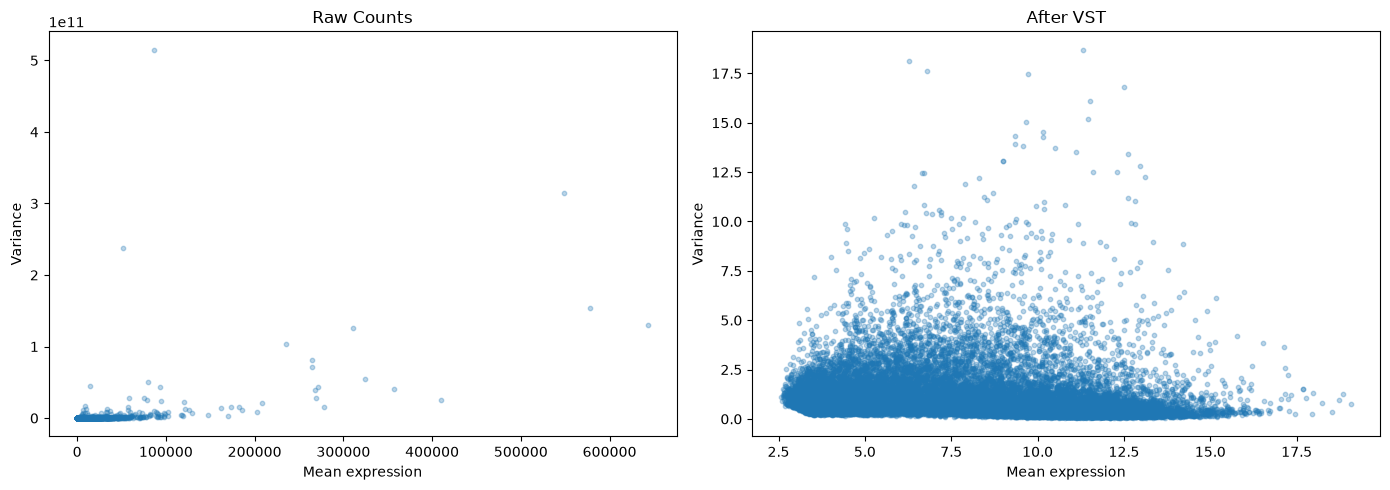

In [18]:
# Calculate mean and variance before and after VST
raw_means = counts_filtered.mean(axis=0)
raw_variances = counts_filtered.var(axis=0)

vst_means = vst_df.mean(axis=0)
vst_variances = vst_df.var(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
axes[0].scatter(
    raw_means,
    raw_variances,
    alpha=0.3,
    s=10
)
axes[0].set_title("Raw Counts")
axes[0].set_xlabel("Mean expression")
axes[0].set_ylabel("Variance")

# VST
axes[1].scatter(
    vst_means,
    vst_variances,
    alpha=0.3,
    s=10
)
axes[1].set_title("After VST")
axes[1].set_xlabel("Mean expression")
axes[1].set_ylabel("Variance")

plt.tight_layout()
plt.show()


In [32]:
# Select the 5,000 most variable genes
n_top_genes = 5000

gene_variances = vst_df.var(axis=0)
top_variable_genes = gene_variances.nlargest(n_top_genes).index

vst_top = vst_df.loc[:, top_variable_genes]

# Calculate sample-to-sample Pearson correlations
sample_correlations = vst_top.T.corr(method="pearson")

print(f"Genes used: {vst_top.shape[1]}")
print(f"Correlation matrix shape: {sample_correlations.shape}")

Genes used: 5000
Correlation matrix shape: (232, 232)


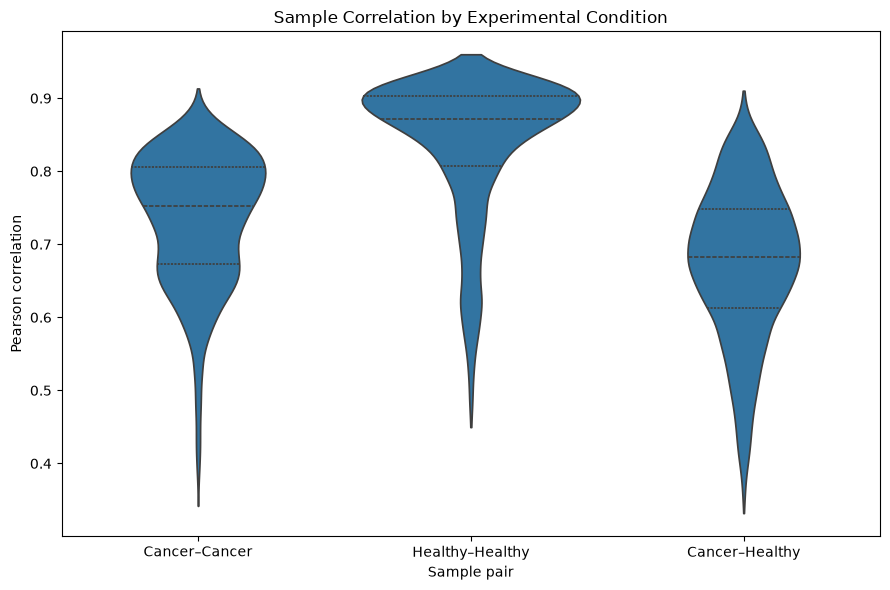

In [33]:
# Get sample conditions in the same order as the correlation matrix
sample_conditions = metadata.loc[
    sample_correlations.index, "Condition"
].to_numpy()

# Extract unique sample pairs (upper triangle)
i, j = np.triu_indices_from(sample_correlations, k=1)

correlation_values = sample_correlations.to_numpy()[i, j]
condition_i = sample_conditions[i]
condition_j = sample_conditions[j]

# Classify sample pairs
pair_types = np.where(
    condition_i == condition_j,
    condition_i + "–" + condition_j,
    "Cancer–Healthy"
)

pairwise_df = pd.DataFrame({
    "Pair type": pair_types,
    "Correlation": correlation_values
})

# Visualize correlation distributions
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=pairwise_df,
    x="Pair type",
    y="Correlation",
    order=[
        "Cancer–Cancer",
        "Healthy–Healthy",
        "Cancer–Healthy"
    ],
    inner="quart",
    cut=0
)

plt.title("Sample Correlation by Experimental Condition")
plt.xlabel("Sample pair")
plt.ylabel("Pearson correlation")
plt.tight_layout()
plt.show()

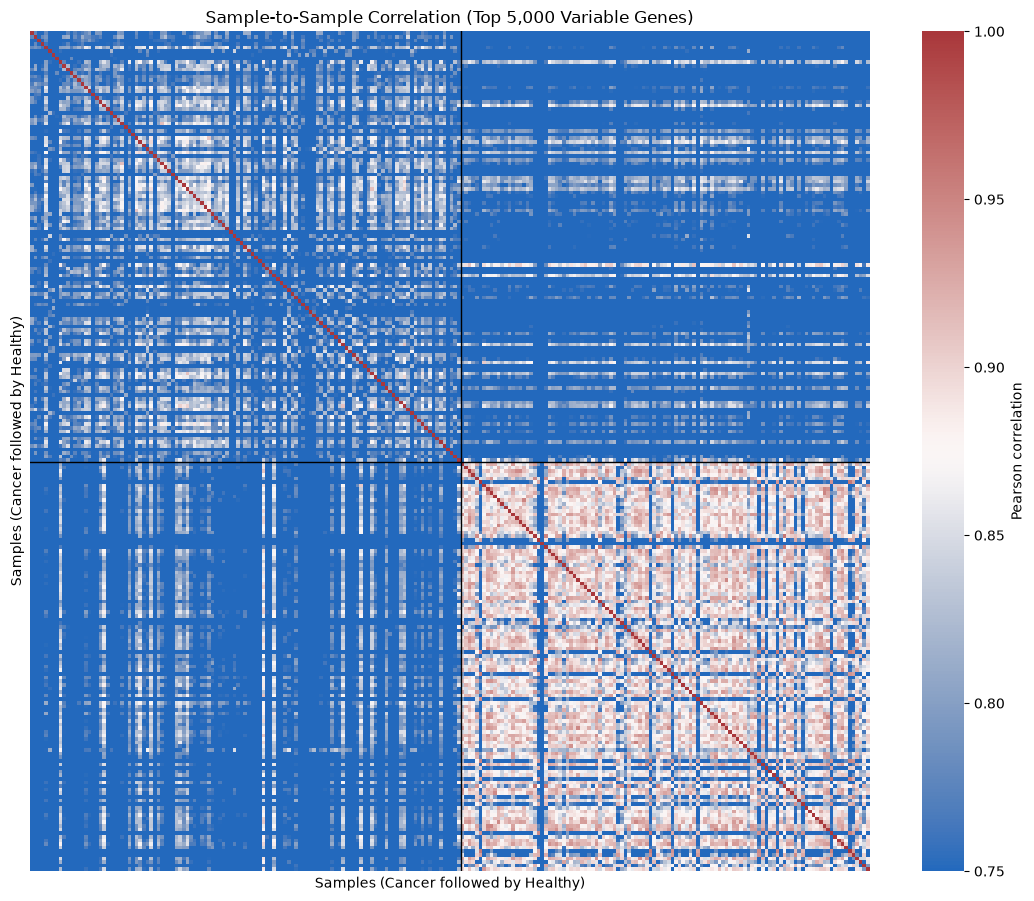

In [31]:
# Order samples by experimental condition
condition_order = pd.Categorical(
    metadata.loc[sample_correlations.index, "Condition"],
    categories=["Cancer", "Healthy"],
    ordered=True
)

ordered_samples = (
    pd.DataFrame({
        "Sample": sample_correlations.index,
        "Condition": condition_order
    })
    .sort_values("Condition")["Sample"]
    .tolist()
)

ordered_correlations = sample_correlations.loc[
    ordered_samples, ordered_samples
]

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    ordered_correlations,
    cmap="vlag",
    vmin=0.75,
    vmax=1.0,
    xticklabels=False,
    yticklabels=False,
    square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)

# Separate the two experimental conditions
n_cancer = (metadata.loc[ordered_samples, "Condition"] == "Cancer").sum()

ax.axhline(n_cancer, color="black", linewidth=1)
ax.axvline(n_cancer, color="black", linewidth=1)

ax.set_title("Sample-to-Sample Correlation (Top 5,000 Variable Genes)")
ax.set_xlabel("Samples (Cancer followed by Healthy)")
ax.set_ylabel("Samples (Cancer followed by Healthy)")

plt.tight_layout()
plt.show()